# 05 · Interactions and the event loop

Three kinds of event occur, each at a time known in closed form:

| event | what happens |
| --- | --- |
| **collision** | adjacent fronts meet; the cluster is replaced by the Riemann solution between its exterior levels |
| **corner** | a front reaches a node where $g_\Delta\ne0$; it switches law, and nothing is emitted |
| **absorption** | a front reaches a zero of $g$ and merges into the interface there |

Events wait in a priority queue with lazy invalidation. With levels on δZ,
the interaction argument of HetFT Theorem 2.4 gives **at most one front**
(none when the exterior states agree). As a
result the front count and the total variation of θ never increase.

In [1]:
# Use the local checkout if present; otherwise install from GitHub (needs the repository to be public).
import sys, subprocess, importlib.util
from pathlib import Path
local_src = next((p / "src" for p in (Path.cwd(), *Path.cwd().parents)
                  if (p / "src/hetfront/__init__.py").is_file()), None)
if local_src is not None:
    sys.path.insert(0, str(local_src))
elif importlib.util.find_spec("hetfront") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/parasuramv/heterogeneous-front-tracking"])
import numpy as np
import matplotlib.pyplot as plt
import hetfront
from hetfront import (HeteroFrontTracker, PeriodicHeteroFrontTracker, MultiplicativeFlux,
                      PiecewiseAffine, trajectory)
from hetfront.visualization import (observe_tracker, plot_spacetime, plot_profile,
                                    plot_heterogeneity, plot_diagnostics, plot_circle, overview)
%matplotlib inline
plt.rcParams["figure.dpi"] = 100
print("hetfront", hetfront.__version__, "from", "local checkout" if local_src else "installed package")

hetfront 0.1.0 from local checkout


## Random experiments: the invariants
Random well-signed heterogeneities and random step data. We record the front count, TV(θ), and the number of collisions with more than one outgoing front, which Theorem 2.4 says should be zero.

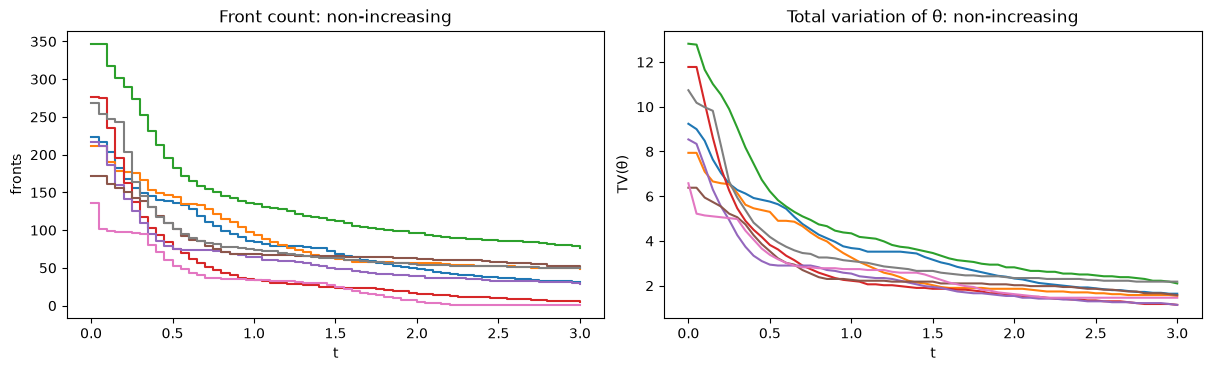

collisions with more than one outgoing front: 0


In [2]:
rng = np.random.default_rng(11)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), constrained_layout=True)
multi = 0
for trial in range(8):
    amp, freq, phase = rng.uniform(0.3, 1.2), rng.uniform(1, 4), rng.uniform(0, 6)
    g = PiecewiseAffine.from_function(lambda x: 2 + amp * np.sin(freq * x + phase), np.linspace(-6, 6, 61))
    flux = MultiplicativeFlux(g, 0.02)
    pos = np.sort(rng.uniform(-3, 3, 12))
    tr = HeteroFrontTracker(flux, pos, rng.integers(-60, 61, 13))
    ts, count, tv = np.linspace(0, 3, 61), [], []
    for t in ts:
        tr.run(t); count.append(tr.front_count()); tv.append(tr.total_variation())
    multi += tr.counts["multi_front_collision"]
    axes[0].step(ts, count, where="post"); axes[1].plot(ts, tv)
axes[0].set(xlabel="t", ylabel="fronts", title="Front count: non-increasing")
axes[1].set(xlabel="t", ylabel="TV(θ)", title="Total variation of θ: non-increasing")
plt.show()
print("collisions with more than one outgoing front:", multi)

## Anatomy of a run
Event counts by kind, together with the space–time picture. Corner events dominate on fine meshes, which is why each one is cheap: a re-anchoring and no Riemann solve.

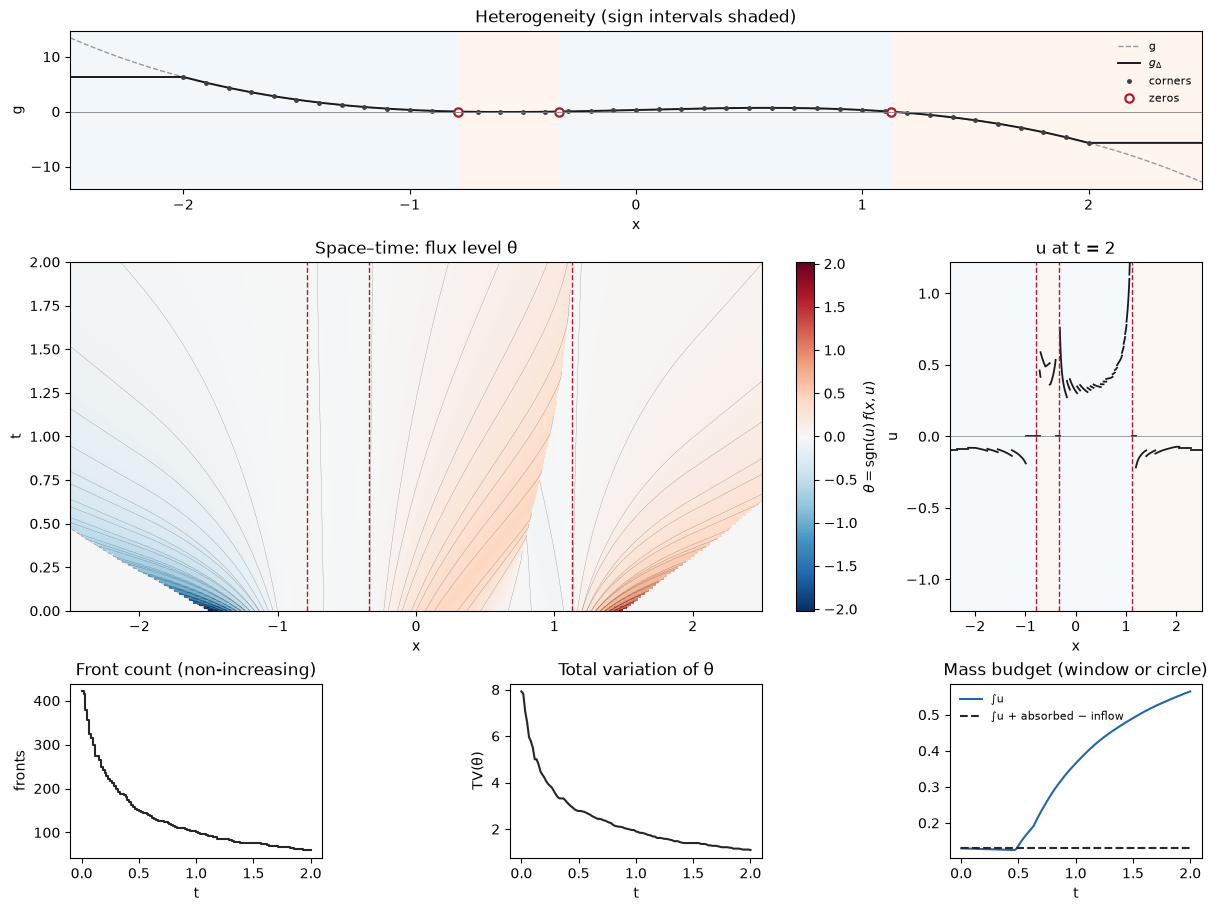

{'collision': 360, 'corner': 2089, 'absorption': 1, 'initial_emission': 1}


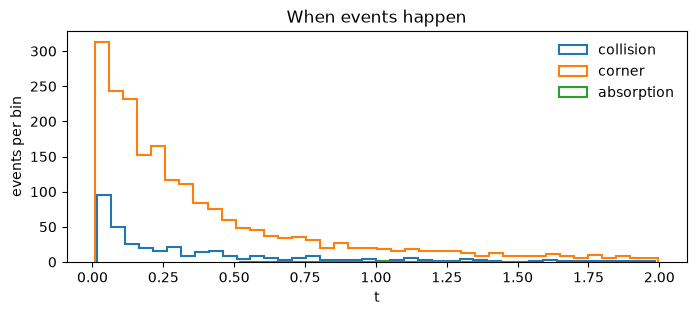

In [3]:
g_exact = lambda x: x * (1 - x**2) + 0.3
g = PiecewiseAffine.from_function(g_exact, np.linspace(-2, 2, 41))
flux = MultiplicativeFlux(g, 0.01)
tr = HeteroFrontTracker.from_function(flux, lambda x: np.where(np.abs(x) < 1.5, np.cos(2 * x), 0.0),
                                      (-1.5, 1.5), cells=90)
h = observe_tracker(tr, np.linspace(-2.5, 2.5, 801), np.linspace(0, 2, 121))
overview(h, exact_g=g_exact)
plt.show()
print({k: v for k, v in tr.counts.items() if v})
kinds = np.array([k for _, _, k in tr.events])
times = np.array([t for t, _, _ in tr.events])
fig, ax = plt.subplots(figsize=(8, 3))
for kind in ("collision", "corner", "absorption"):
    ax.hist(times[kinds == kind], bins=40, histtype="step", lw=1.5, label=kind)
ax.set(xlabel="t", ylabel="events per bin", title="When events happen")
ax.legend(frameon=False)
plt.show()

## Cost versus resolution
The number of events grows like (fronts) × (cells crossed). Halving δ doubles the number of fronts, and halving Δ doubles the number of corners.

In [4]:
import time
rows = []
for delta in (0.04, 0.02, 0.01):
    for nodes in (21, 41, 81):
        g = PiecewiseAffine.from_function(lambda x: 2 + np.sin(3 * x), np.linspace(-4, 4, nodes))
        flux = MultiplicativeFlux(g, delta)
        start = time.perf_counter()
        tr = HeteroFrontTracker.from_function(flux, lambda x: np.where(np.abs(x) < 1, np.cos(np.pi * x / 2), 0.0),
                                              (-1, 1), cells=40, record_history=False).run(2.0)
        rows.append((delta, nodes, tr.counts["collision"], tr.counts["corner"], time.perf_counter() - start))
print(" delta  nodes  collisions  corners  seconds")
for r in rows:
    print(f"{r[0]:6.3f} {r[1]:6d} {r[2]:11d} {r[3]:8d} {r[4]:8.3f}")

 delta  nodes  collisions  corners  seconds
 0.040     21          56      331    0.019
 0.040     41          59      669    0.027
 0.040     81          58     1323    0.045
 0.020     21         100      642    0.038
 0.020     41         104     1293    0.054
 0.020     81         104     2583    0.095
 0.010     21         184     1265    0.060
 0.010     41         192     2538    0.087
 0.010     81         191     5050    0.143


## The homogeneous special case
For constant $g = b$ the scheme is Dafermos front tracking for $bu^2$ on the nonuniform state grid $U[\delta\mathbb Z]$. If the homogeneous solver [`fronttrack`](https://github.com/parasuramv/scalar-front-tracking) is installed, or `HOMO_FRONT_TRACKING_PATH` names a checkout of it, the two codes agree to roundoff.

In [5]:
import importlib, os
homo = Path(os.environ.get("HOMO_FRONT_TRACKING_PATH", ".")).expanduser() / "src"
if importlib.util.find_spec("fronttrack") is None and (homo / "fronttrack").is_dir():
    sys.path.insert(0, str(homo))
try:
    import fronttrack as ft
except ImportError:
    print("fronttrack not available: skipping the comparison")
else:
    b, delta = 1.5, 0.05
    flux = MultiplicativeFlux(PiecewiseAffine.constant(b), delta)
    ks = np.arange(-40, 41)
    grid = flux.s(ks) / np.sqrt(b)
    rng = np.random.default_rng(3)
    pos, lev = np.sort(rng.uniform(-3, 3, 25)), rng.integers(-30, 31, 26)
    ours = HeteroFrontTracker(flux, pos, lev).run(4.0)
    ref = ft.FrontTracker(ft.DiscreteFlux(lambda u: b * u**2, grid), pos, lev + 40).run(4.0)
    print("fronts:", ours.front_count(), "vs", len(ref.fronts))
    print("max position difference:", np.max(np.abs(ours.positions() - [f.x for f in ref.fronts])))

fronts: 19 vs 19
max position difference: 3.730349362740526e-14
